# Baseline LightGBM — rel-hm / item-sales

**Tâche** : prédire le chiffre d'affaires (`sales`) de chaque article H&M sur les 7 prochains jours.

**Split officiel RelBench** :
- Train : 2019-09-09 → 2020-08-31 (hebdomadaire)
- Val   : 2020-09-07 (1 semaine)
- Test  : 2020-09-14 (1 semaine)

**Approche** : table plate — features statiques article + features temporelles + lag features (ventes semaine précédente).

In [3]:
#!pip install lightgbm relbench -q

In [4]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import lightgbm as lgb
import sklearn; sklearn.set_config(display='text')
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from relbench.tasks import get_task

# RelBench cherche les données en chemin relatif "data/hm-recommendation"
# → on se place à la racine du projet (parent de notebooks/)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)

print("Chargement du dataset rel-hm...")
task = get_task('rel-hm', 'item-sales', download=False)
db   = task.dataset.get_db()

articles_df  = db.table_dict['article'].df.copy()
print(f"Articles   : {len(articles_df):,}")
print(f"Clients    : {len(db.table_dict['customer'].df):,}")
print(f"Transactions: {len(db.table_dict['transactions'].df):,}")

Chargement du dataset rel-hm...
Articles   : 105,542
Clients    : 1,371,980
Transactions: 15,187,287


## 1. Chargement des tables de tâche

In [5]:
train_tbl = task.get_table("train")
val_tbl   = task.get_table("val")
test_tbl  = task.get_table("test")

df_train = train_tbl.df.copy()
df_val   = val_tbl.df.copy()
df_test  = test_tbl.df.copy()

print(f"Train : {len(df_train):,} lignes  {df_train['timestamp'].min().date()} → {df_train['timestamp'].max().date()}")
print(f"Val   : {len(df_val):,} lignes  {df_val['timestamp'].unique()[0].date()}")
print(f"Test  : {len(df_test):,} lignes  {df_test['timestamp'].unique()[0].date()}")
print(f"\nTarget (sales) :")
print(df_train['sales'].describe().round(4))
print(f"% zéros train : {(df_train['sales']==0).mean()*100:.1f}%")

Making task table for train split from scratch...
Loading Database object from /home/infres/sryszfeld-24/.cache/relbench/rel-hm/db...
Done in 2.20 seconds.


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Done in 12.63 seconds.
Making task table for val split from scratch...
Done in 0.28 seconds.
Making task table for test split from scratch...
Loading Database object from /home/infres/sryszfeld-24/.cache/relbench/rel-hm/db...
Done in 2.24 seconds.
Done in 2.58 seconds.
Train : 5,488,184 lignes  2019-09-09 → 2020-08-31
Val   : 105,542 lignes  2020-09-07
Test  : 105,542 lignes  2020-09-14

Target (sales) :
count    5.488184e+06
mean     7.600000e-02
std      4.953000e-01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      8.716260e+01
Name: sales, dtype: float64
% zéros train : 81.4%


## 2. Features statiques — attributs article

In [6]:
# Colonnes catégorielles informatives de la table article
CAT_COLS = [
    'product_type_name', 'product_group_name', 'graphical_appearance_name',
    'colour_group_name', 'department_name', 'index_name',
    'section_name', 'garment_group_name',
]

enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
articles_enc = articles_df[['article_id'] + CAT_COLS].copy()
articles_enc[CAT_COLS] = enc.fit_transform(articles_enc[CAT_COLS].astype(str)).astype('int32')

def add_article_features(df):
    return df.merge(articles_enc, on='article_id', how='left')

df_train = add_article_features(df_train)
df_val   = add_article_features(df_val)
df_test  = add_article_features(df_test)

print("Features article ajoutées :", CAT_COLS)

Features article ajoutées : ['product_type_name', 'product_group_name', 'graphical_appearance_name', 'colour_group_name', 'department_name', 'index_name', 'section_name', 'garment_group_name']


## 3. Features temporelles

In [7]:
def add_time_features(df):
    df = df.copy()
    df['week_of_year'] = df['timestamp'].dt.isocalendar().week.astype('int32')
    df['month']        = df['timestamp'].dt.month.astype('int32')
    df['year']         = df['timestamp'].dt.year.astype('int32')
    return df

df_train = add_time_features(df_train)
df_val   = add_time_features(df_val)
df_test  = add_time_features(df_test)

print("Features temporelles : week_of_year, month, year")

Features temporelles : week_of_year, month, year


## 4. Lag features (ventes semaine précédente)

Le train est un panel complet article × semaine (timestamps hebdomadaires).
`lag1` = ventes de la semaine précédente pour le même article.

Pour val  : lag1 = dernière ligne train par article (semaine [2020-08-31, 2020-09-07]).
Pour test : lag1 = ventes val (semaine [2020-09-07, 2020-09-14]).

In [8]:
# Train : lag features via shift sur le panel (article_id, timestamp) trié
df_train = df_train.sort_values(['article_id', 'timestamp'])
df_train['lag1'] = df_train.groupby('article_id')['sales'].shift(1)
df_train['lag2'] = df_train.groupby('article_id')['sales'].shift(2)
df_train['lag4'] = df_train.groupby('article_id')['sales'].shift(4)
df_train['ma4']  = df_train.groupby('article_id')['sales'].transform(
    lambda x: x.shift(1).rolling(4, min_periods=1).mean())

# Val : lag features = dernière ligne du train par article
# groupby(as_index=False).last() → DataFrame avec article_id en colonne (robuste pandas 2.x)
last_row = (df_train
            .sort_values(['article_id', 'timestamp'])
            .groupby('article_id', as_index=False)[['sales', 'lag1', 'lag2', 'ma4']]
            .last())
# Renommer : le sales de la dernière semaine train = lag1 pour val, etc.
last_row = last_row.rename(columns={
    'sales': 'lag1',   # semaine [2020-08-31, 2020-09-07] → lag1 de val
    'lag1' : 'lag2',   # semaine [2020-08-24, 2020-08-31] → lag2 de val
    'lag2' : 'lag4',   # approximation lag4
    'ma4'  : 'ma4',
})
df_val = df_val.merge(last_row[['article_id', 'lag1', 'lag2', 'lag4', 'ma4']],
                      on='article_id', how='left')

# Test : lag features = ventes de val + lag features de val
test_lag = df_val[['article_id', 'sales', 'lag1', 'lag2', 'ma4']].copy()
test_lag = test_lag.rename(columns={
    'sales': 'lag1',
    'lag1' : 'lag2',
    'lag2' : 'lag4',
    'ma4'  : 'ma4',
})
df_test = df_test.merge(test_lag[['article_id', 'lag1', 'lag2', 'lag4', 'ma4']],
                        on='article_id', how='left')

print(f"NaN lag1  train : {df_train['lag1'].isna().sum():,}  (1re semaine par article)")
print(f"NaN lag1  val   : {df_val['lag1'].isna().sum():,}")
print(f"NaN lag1  test  : {df_test['lag1'].isna().sum():,}")


NaN lag1  train : 105,542  (1re semaine par article)
NaN lag1  val   : 0
NaN lag1  test  : 0


## 5. Entraînement LightGBM

In [9]:
FEATURES = CAT_COLS + ['week_of_year', 'month', 'year', 'lag1', 'lag2', 'lag4', 'ma4']
TARGET   = 'sales'

# Note : test_tbl de RelBench n'a pas de colonne 'sales' (labels cachés — leaderboard officiel).
# Setup propre :
#   • inner_val = dernière semaine du train (early stopping, jamais vu par le modèle final)
#   • val officiel RelBench (timestamp = 2020-09-07) = évaluation finale

LAST_TRAIN_TS = df_train['timestamp'].max()
inner_train = df_train[df_train['timestamp'] < LAST_TRAIN_TS]
inner_val   = df_train[df_train['timestamp'] == LAST_TRAIN_TS]

X_inner_train, y_inner_train = inner_train[FEATURES], inner_train[TARGET]
X_inner_val,   y_inner_val   = inner_val[FEATURES],   inner_val[TARGET]
X_eval,        y_eval        = df_val[FEATURES],       df_val[TARGET]

print(f"Inner train : {len(X_inner_train):,} lignes (jusqu'au {LAST_TRAIN_TS.date() - pd.Timedelta(days=7)})")
print(f"Inner val   : {len(X_inner_val):,} lignes  ({LAST_TRAIN_TS.date()} — early stopping)")
print(f"Eval final  : {len(X_eval):,} lignes  (2020-09-07 — val officiel RelBench)")

model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=-1,
)

model.fit(
    X_inner_train, y_inner_train,
    categorical_feature=CAT_COLS,
    eval_set=[(X_inner_val, y_inner_val)],
    callbacks=[lgb.early_stopping(50, verbose=True)],
)

print(f"\nModèle entraîné — {model.best_iteration_} arbres")


Inner train : 5,382,642 lignes (jusqu'au 2020-08-24)
Inner val   : 105,542 lignes  (2020-08-31 — early stopping)
Eval final  : 105,542 lignes  (2020-09-07 — val officiel RelBench)
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[74]	valid_0's l2: 0.098058

Modèle entraîné — 74 arbres


## 6. Évaluation

In [10]:
y_pred = model.predict(X_eval)
y_true = y_eval.values

mae  = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
r2   = r2_score(y_true, y_pred)

# Baseline persistance : prédire lag1 (ventes semaine précédente) 
# On dit que les ventes d'ajd sont les mêmes que celles de la semaine derniere
lag1_pred = X_eval['lag1'].fillna(0).values
mae_p  = mean_absolute_error(y_true, lag1_pred)
rmse_p = np.sqrt(mean_squared_error(y_true, lag1_pred))
r2_p   = r2_score(y_true, lag1_pred)

# Baseline naïve : moyenne du train
mean_pred = np.full(len(y_true), y_inner_train.mean())
mae_m  = mean_absolute_error(y_true, mean_pred)
rmse_m = np.sqrt(mean_squared_error(y_true, mean_pred))

print("Évaluation sur val officiel RelBench (timestamp = 2020-09-07)")
print(f"{'Métrique':<10} {'LightGBM':>12} {'Persistance':>14} {'Naïve (mean)':>15}")
print(f"{'-'*55}")
print(f"{'MAE':<10} {mae:>12.4f} {mae_p:>14.4f} {mae_m:>15.4f}")
print(f"{'RMSE':<10} {rmse:>12.4f} {rmse_p:>14.4f} {rmse_m:>15.4f}")
print(f"{'R²':<10} {r2:>12.4f} {r2_p:>14.4f} {'—':>15}")


Évaluation sur val officiel RelBench (timestamp = 2020-09-07)
Métrique       LightGBM    Persistance    Naïve (mean)
-------------------------------------------------------
MAE              0.0501         0.0472          0.1423
RMSE             0.4089         0.4323          0.6624
R²               0.6188         0.5739               —


#### Le verdict est nuancé :

- Tout le monde écrase la naïve → tous les modèles ont appris quelque chose. Le minimum syndical est validé.
- LightGBM bat la persistance sur RMSE et R² → il est meilleur sur les grosses ventes (là où le carré pèse), parce qu'il sait exploiter les features (catégories d'article, lags, etc.) pour anticiper les pics.
- Mais la persistance bat LightGBM sur le MAE → sur la masse des articles (les 81 % à 0 vente), recopier bêtement la semaine précédente fait moins d'erreur moyenne que le modèle, qui « bave » un peu en prédisant des petites valeurs non nulles.
#### Conclusion à en tirer
Le modèle apporte de la valeur uniquement sur les évènements à fort enjeu (les best-sellers). Sur le creux de la distribution, il ne fait pas mieux qu'un copier-coller. C'est le symptôme classique d'une cible très déséquilibrée (81 % de zéros) : c'est précisément pourquoi le notebook montre les deux baselines — pour révéler que « R² = 0.61 » sonne bien mais cache une victoire partielle.

Pistes si tu veux que LightGBM domine partout : modéliser le problème en deux temps (classif « vend / vend pas » puis régression sur les non-zéros), ou optimiser directement le MAE (objective='mae') plutôt que la MSE par défaut.

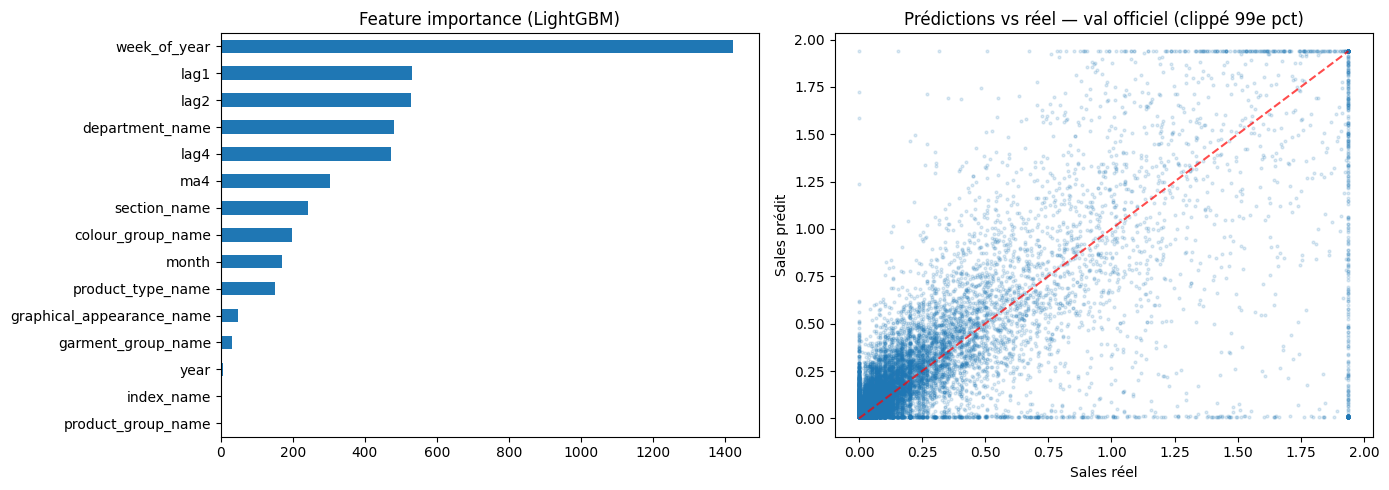

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind='barh', ax=axes[0], title='Feature importance (LightGBM)')

clip = np.percentile(y_true, 99)
axes[1].scatter(np.clip(y_true, 0, clip), np.clip(y_pred, 0, clip), alpha=0.15, s=4)
axes[1].plot([0, clip], [0, clip], 'r--', alpha=0.7)
axes[1].set_xlabel('Sales réel'); axes[1].set_ylabel('Sales prédit')
axes[1].set_title('Prédictions vs réel — val officiel (clippé 99e pct)')
plt.tight_layout(); plt.show()
